In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
datasets_colors = {'BBBC039':'#FFC0CB',
                   'mnfinder':'#80ED99',
                   'mnDINO_data_01':'#192A56',
                   'mnDINO_data_02':'#00A3FF'}

objects_color = {'Nuc':'#00A3FF',
                 'MN':'#A68CFF'}

# plt.rcParams.update({'font.size':12})

# sns.set(font_scale=1.5, style='white')

In [3]:
table_path = '/hdd/jcaicedo/projects/micronuclei_detection/Train_and_Eval/mndino_data/figures/loss_ablation.csv'
table = pd.read_csv(table_path)
table

,Datasets,Precision,Recall,Inference Time,Ablation
0,BBBC039,0.58,0.79,2.465127,MN (80%) Nuc (20%)
1,Pilot_Screen,0.79,0.88,139.749729,MN (80%) Nuc (20%)
2,HeLa_RPE1,0.80,0.88,118.159393,MN (80%) Nuc (20%)
3,MNFinder Data,0.84,0.75,2.934100,MN (80%) Nuc (20%)
4,BBBC039,0.58,0.85,2.540284,MN (20%) Nuc (80%)
5,Pilot_Screen,0.70,0.88,141.898294,MN (20%) Nuc (80%)
6,HeLa_RPE1,0.70,0.93,119.172164,MN (20%) Nuc (80%)
7,MNFinder Data,0.85,0.84,2.980917,MN (20%) Nuc (80%)
8,BBBC039,0.59,0.90,2.513101,MN (50%) Nuc (50%)
9,Pilot_Screen,0.67,0.93,139.306722,MN (50%) Nuc (50%)


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

table['F1'] = 2 * table['Precision'] * table['Recall'] / (table['Precision'] + table['Recall'])
table['MN weight (%)'] = table['Ablation'].str.extract(r'MN \((\d+)%\)').astype(int)

In [5]:
table

,Datasets,Precision,Recall,Inference Time,Ablation,F1,MN weight (%)
0,BBBC039,0.58,0.79,2.465127,MN (80%) Nuc (20%),0.668905,80
1,Pilot_Screen,0.79,0.88,139.749729,MN (80%) Nuc (20%),0.832575,80
2,HeLa_RPE1,0.80,0.88,118.159393,MN (80%) Nuc (20%),0.838095,80
3,MNFinder Data,0.84,0.75,2.934100,MN (80%) Nuc (20%),0.792453,80
4,BBBC039,0.58,0.85,2.540284,MN (20%) Nuc (80%),0.689510,20
5,Pilot_Screen,0.70,0.88,141.898294,MN (20%) Nuc (80%),0.779747,20
6,HeLa_RPE1,0.70,0.93,119.172164,MN (20%) Nuc (80%),0.798773,20
7,MNFinder Data,0.85,0.84,2.980917,MN (20%) Nuc (80%),0.844970,20
8,BBBC039,0.59,0.90,2.513101,MN (50%) Nuc (50%),0.712752,50
9,Pilot_Screen,0.67,0.93,139.306722,MN (50%) Nuc (50%),0.778875,50


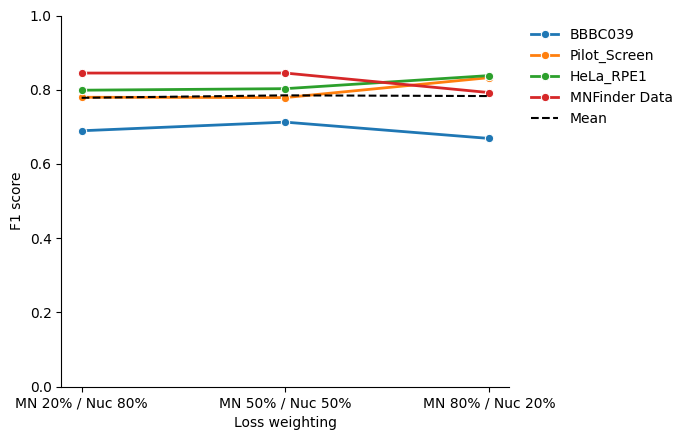

In [6]:
plt.figure(figsize=(7, 4.5))
ax = sns.lineplot(data=table, x='MN weight (%)', y='F1', hue='Datasets', marker='o', linewidth=2)
sns.lineplot(data=table, x='MN weight (%)', y='F1', color='black', linestyle='--',
             errorbar=None, label='Mean', ax=ax)   # average across datasets

ax.set_xticks([20, 50, 80])
ax.set_xticklabels(['MN 20% / Nuc 80%', 'MN 50% / Nuc 50%', 'MN 80% / Nuc 20%'])
ax.set_ylabel('F1 score')
ax.set_xlabel('Loss weighting')
ax.set_ylim(0, 1)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine()
plt.tight_layout()
plt.show()